<a href="https://colab.research.google.com/github/Vinyasbms2006/OS-lab/blob/main/newhouse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Importing Libraries and Loading the Dataset**
Description: Import the required Python libraries and load the Bengaluru house dataset into a Pandas DataFrame for further analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('Bengaluru_House_Data.csv')

# Display the first five rows
df.head()

Saving Bengaluru_House_Data.csv to Bengaluru_House_Data.csv


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


**2. Initial Data Exploration**
Description: Examine the dataset's dimensions, column names, data types and basic information to understand its structure.

In [3]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Shape: (13320, 9)

Column Names:
Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB

Statistical Summary:


,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


**3. Identifying Numerical and Categorical Variables**
Description: Separate numerical and categorical columns to understand the types of data available for analysis.

In [4]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include='object').columns.tolist()

print("Numerical Variables:")
print(numerical_columns)

print("\nCategorical Variables:")
print(categorical_columns)

Numerical Variables:
['bath', 'balcony', 'price']

Categorical Variables:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft']


**4. Checking Duplicate Records**
Description: Identify completely duplicated rows in the dataset.

In [5]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

# Remove exact duplicate records
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Number of Duplicate Rows: 529
Shape after removing duplicates: (12791, 9)


**Inference:** The original dataset contains 529 exact duplicate rows. These are removed to avoid counting identical records multiple times. Exact duplicates are not necessarily proof of duplicate real-world property listings, so mention this limitation in your report.

**5. Missing Value Analysis**
Description: Identify missing values in each column and calculate their percentages.

In [6]:
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_values)

,Missing Count,Missing Percentage
society,5328,41.654288
balcony,605,4.729888
bath,73,0.570714
size,16,0.125088
location,1,0.007818
area_type,0,0.000000
availability,0,0.000000
total_sqft,0,0.000000
price,0,0.000000


**Visualizing Missing Values**

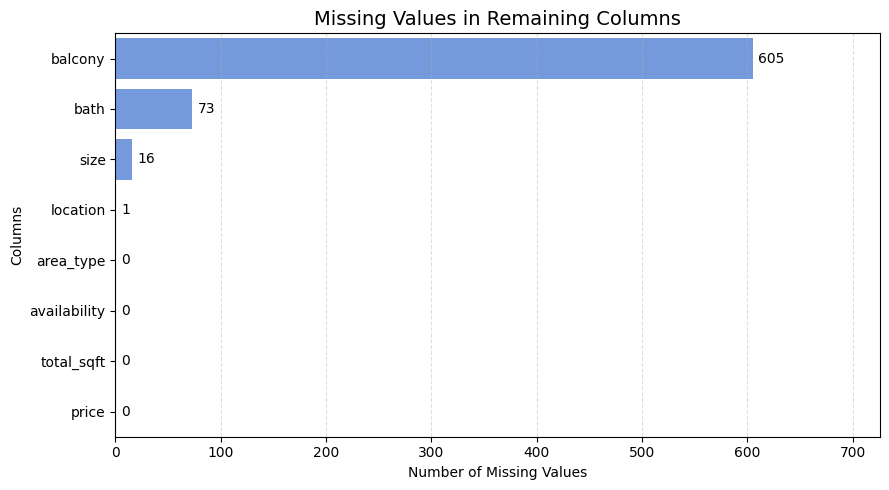

In [10]:
missing_other = missing_values.drop('society', errors='ignore')

plt.figure(figsize=(9, 5))

# Explicitly use the 'Missing Count' column to ensure a 1-dimensional array
ax = sns.barplot(
    x=missing_other['Missing Count'].values,
    y=missing_other.index,
    color='cornflowerblue'
)

for i, value in enumerate(missing_other['Missing Count'].values):
    ax.text(value + 5, i, str(value), va='center')

plt.title("Missing Values in Remaining Columns", fontsize=14)
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.xlim(0, max(missing_other['Missing Count'].values) * 1.2)
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Observation: The initial bar chart uses a linear scale. Since the society column contains significantly more missing values than the other columns, the smaller bars are compressed and difficult to distinguish. Therefore, the graph does not provide a clear comparison of missing values across all columns. To improve readability, a logarithmic scale is used in the revised visualization.

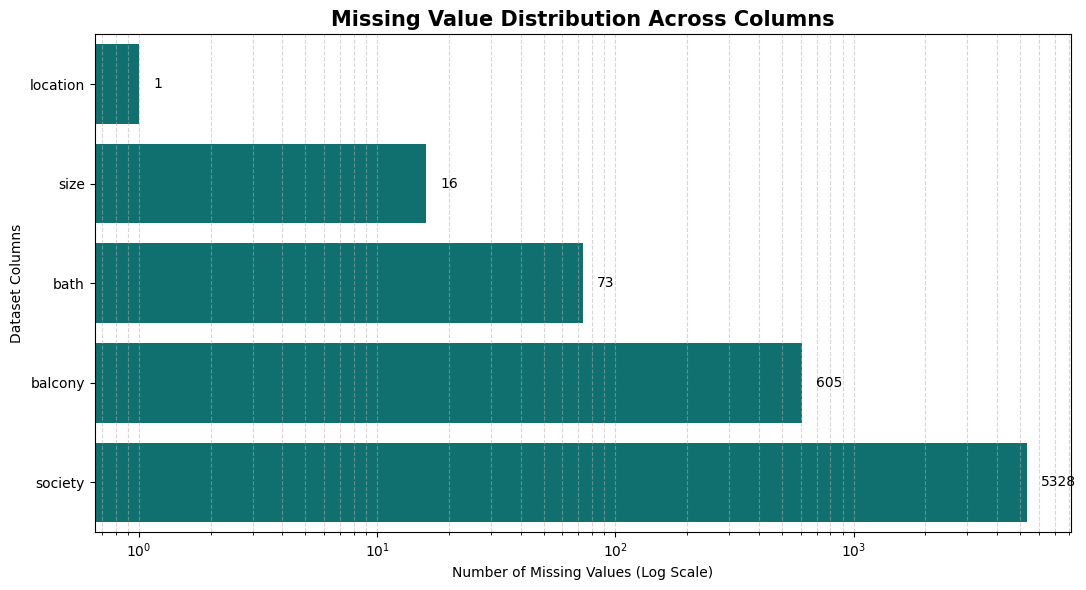

In [11]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values()

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=missing.values,
    y=missing.index,
    color='teal'
)

# Apply logarithmic scale
ax.set_xscale('log')

# Display exact values
for i, value in enumerate(missing.values):
    ax.text(value * 1.15, i, str(value), va='center', fontsize=10)

plt.title("Missing Value Distribution Across Columns",
          fontsize=15, fontweight='bold')

plt.xlabel("Number of Missing Values (Log Scale)")
plt.ylabel("Dataset Columns")

plt.grid(axis='x', linestyle='--', alpha=0.5, which='both')
plt.tight_layout()
plt.show()

Inference: Missing Value Analysis
The logarithmic-scale bar chart shows that missing values are unevenly distributed across the Bengaluru House Data dataset. The society column has the highest number of missing values, followed by balcony, while bath, size and location contain comparatively fewer missing values. The remaining columns have no missing values.

This indicates that the society and balcony attributes have comparatively more incomplete information. Therefore, suitable missing-value handling techniques should be applied based on the nature and importance of each column before proceeding with further analysis.

Observation: The logarithmic scale makes it easier to visualize and compare columns with both large and small missing-value counts.


In [12]:
# Fill missing society values with Unknown
df['society'] = df['society'].fillna('Unknown')

# Remove rows where location is missing
df = df.dropna(subset=['location'])

# Remove rows where size is missing
df = df.dropna(subset=['size'])

# Fill missing bath values using median bath count
# for the corresponding house size
df['bath'] = df.groupby('size')['bath'].transform(
    lambda x: x.fillna(x.median())
)

# Fill any remaining missing bath values with overall median
df['bath'] = df['bath'].fillna(df['bath'].median())

# Fill missing balcony values using median
# for the corresponding house size
df['balcony'] = df.groupby('size')['balcony'].transform(
    lambda x: x.fillna(x.median())
)

# Fill any remaining missing balcony values with overall median
df['balcony'] = df['balcony'].fillna(df['balcony'].median())

print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
area_type       0
availability    0
location        0
size            0
society         0
total_sqft      0
bath            0
balcony         0
price           0
dtype: int64


Inference:Missing Value Handling
After applying the appropriate missing-value handling techniques, the dataset contains zero missing values in all columns. Missing values in society were replaced with Unknown, missing records in location and size were removed, and missing values in bath and balcony were imputed using median values.

This ensures that the dataset is complete and ready for further data cleaning, outlier detection and exploratory data analysis.

Observation: The missing-value count is now zero across all 8 columns

**1. Checking Duplicate Records**
Description: Identify duplicate rows in the dataset. Duplicate records can affect the accuracy of statistical analysis.

In [13]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

# Remove duplicate records
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Number of Duplicate Records: 1
Dataset Shape After Removing Duplicates: (12773, 9)


**Inference: Duplicate Record Analysis**
The dataset initially contained 1 duplicate record. This duplicate was identified and removed using the drop_duplicates() function.

After removing the duplicate, the dataset contains 12,773 rows and 9 columns. This helps prevent repeated records from affecting subsequent analysis.

Observation: Only one exact duplicate record was found and removed.

**2. Identifying Data Types**
Description: Examine the data types of each column to identify variables that require conversion before analysis.

In [14]:
print("Data Types of Each Column:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Data Types of Each Column:
area_type        object
availability     object
location         object
size             object
society          object
total_sqft       object
bath            float64
balcony         float64
price           float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 12773 entries, 0 to 13318
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     12773 non-null  object 
 1   availability  12773 non-null  object 
 2   location      12773 non-null  object 
 3   size          12773 non-null  object 
 4   society       12773 non-null  object 
 5   total_sqft    12773 non-null  object 
 6   bath          12773 non-null  float64
 7   balcony       12773 non-null  float64
 8   price         12773 non-null  float64
dtypes: float64(3), object(6)
memory usage: 997.9+ KB


**3. Identifying Invalid Values**
Check numerical columns for zero, negative or unrealistic values that may affect the quality of the dataset.

In [15]:
print("Invalid Price:", (df['price'] <= 0).sum())

print("Invalid Bathrooms:", (df['bath'] <= 0).sum())

print("Invalid Balconies:", (df['balcony'] < 0).sum())

print("Missing Values:")
print(df.isnull().sum())

Invalid Price: 0
Invalid Bathrooms: 0
Invalid Balconies: 0
Missing Values:
area_type       0
availability    0
location        0
size            0
society         0
total_sqft      0
bath            0
balcony         0
price           0
dtype: int64


**Inference: Identification of Invalid Values**
The analysis shows that there are no zero or negative values in the price, bath and balcony columns. Additionally, no missing values remain in the dataset after the missing-value handling process.

Therefore, no further corrections are required for these checked conditions. The dataset is suitable for proceeding with outlier analysis.

**Outlier Detection Using Box Plots**
Description: Box plots are used to identify potential outliers and understand the spread of numerical variables.

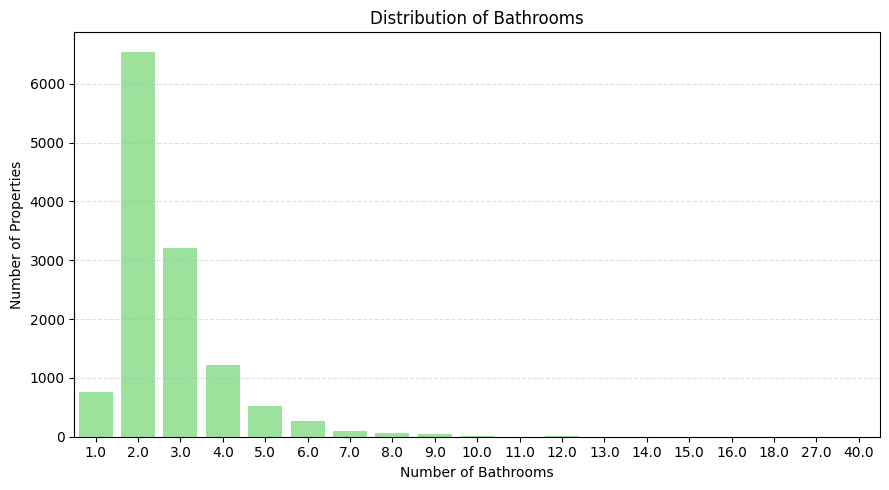

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='bath', color='lightgreen')

plt.title("Distribution of Bathrooms")
plt.xlabel("Number of Bathrooms")
plt.ylabel("Number of Properties")
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**Inference: Distribution of Bathrooms**

The graph indicates that most residential properties in the dataset have two bathrooms, followed by three bathrooms. Properties with four or fewer bathrooms account for the majority of observations. As the number of bathrooms increases, the frequency of properties decreases significantly.

A small number of properties have unusually high bathroom counts, which may represent potential outliers and require further investigation.


**House Price – Box Plot**

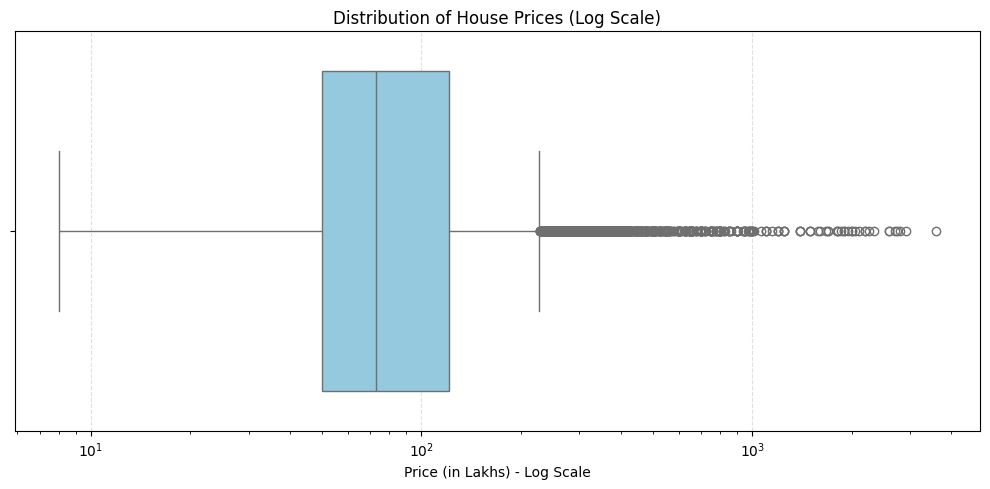

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['price'], color='skyblue')

plt.xscale('log')
plt.title("Distribution of House Prices (Log Scale)")
plt.xlabel("Price (in Lakhs) - Log Scale")
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**Inference: Distribution of House Prices**

The box plot shows that house prices are concentrated within a relatively smaller range, with the median positioned towards the lower side of the overall price distribution. Several individual points appear beyond the upper whisker, indicating potential high-price outliers.

This suggests that the house price distribution is positively skewed, with a small number of properties having considerably higher prices than most properties in the dataset. The logarithmic scale helps visualize this wide variation more clearly.

**Balcony Count – Distribution**

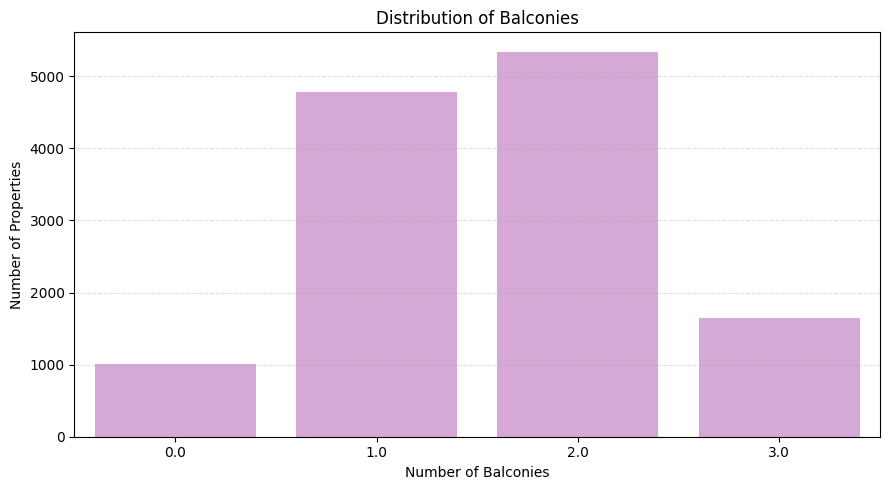

In [18]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='balcony', color='plum')

plt.title("Distribution of Balconies")
plt.xlabel("Number of Balconies")
plt.ylabel("Number of Properties")
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**Inference: Distribution of Balconies**

The graph shows that most properties in the Bengaluru House Data dataset have either one or two balconies. Properties with two balconies are the most common, followed by properties with one balcony. Comparatively, fewer properties have zero or three balconies.

This indicates that residential properties with one or two balconies are more prevalent in the dataset.

### **4. Univariate Analysis**
Explore the distributions, shape (skewness, kurtosis), and summary statistics of individual variables.

Bath: Mean=2.71, Median=2.00, Skewness=4.19, Kurtosis=61.26
Balcony: Mean=1.60, Median=2.00, Skewness=-0.03, Kurtosis=-0.51
Price: Mean=114.35, Median=73.00, Skewness=7.96, Kurtosis=104.93


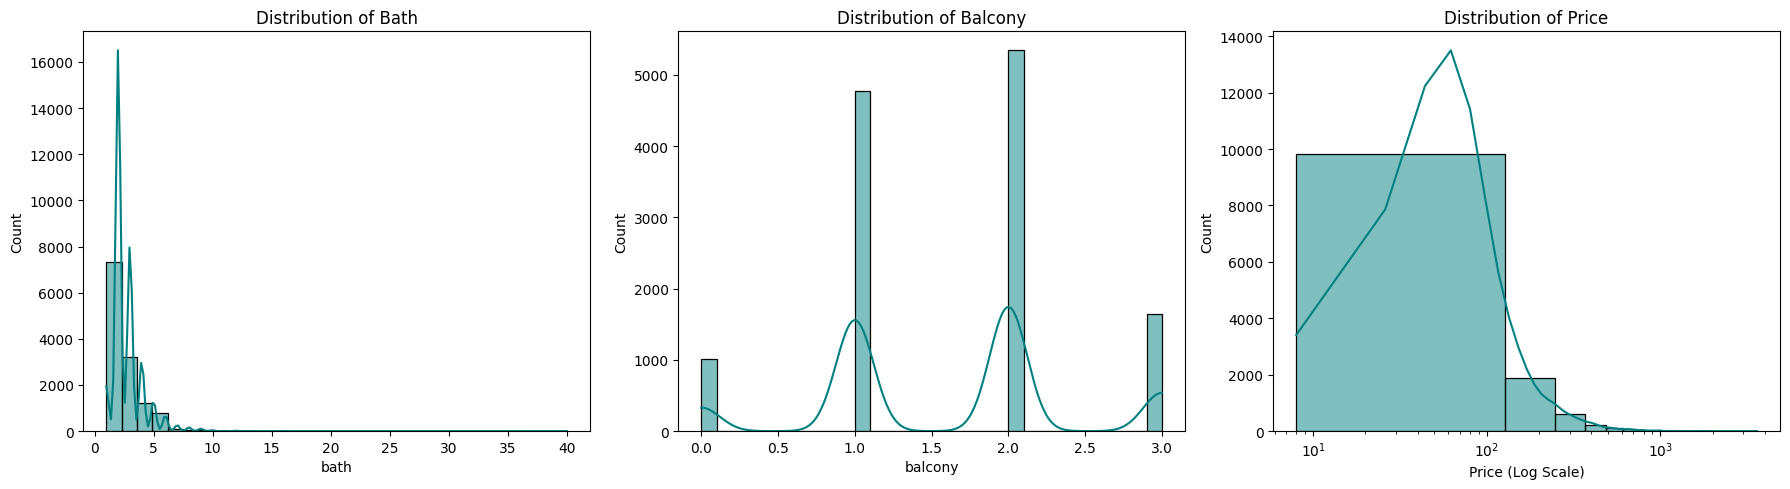

In [19]:
from scipy.stats import skew, kurtosis

# Calculate skewness and kurtosis for numerical columns
for col in ['bath', 'balcony', 'price']:
    col_skew = skew(df[col])
    col_kurt = kurtosis(df[col])
    print(f"{col.capitalize()}: Mean={df[col].mean():.2f}, Median={df[col].median():.2f}, Skewness={col_skew:.2f}, Kurtosis={col_kurt:.2f}")

# Plotting Histograms and KDE plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['bath', 'balcony', 'price']):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f'Distribution of {col.capitalize()}')
    if col == 'price':
        axes[i].set_xscale('log')
        axes[i].set_xlabel('Price (Log Scale)')

plt.tight_layout()
plt.show()

### **5. Bivariate Analysis**
Explore the relationships between pairs of features, such as comparing bathroom counts and prices, or balcony counts and prices.

/tmp/ipykernel_6975/1533137426.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='balcony', y='price', ax=axes[1], palette='Set2')


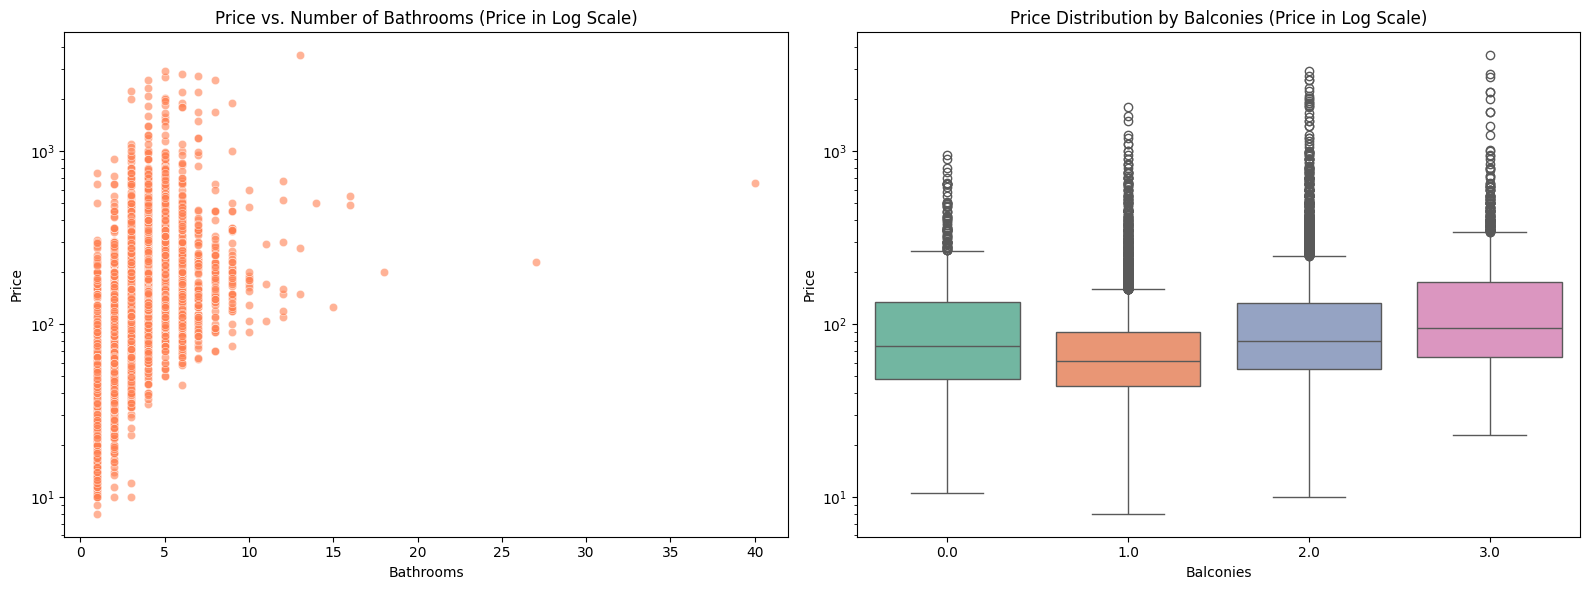

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot between Bathrooms and Price
sns.scatterplot(data=df, x='bath', y='price', ax=axes[0], alpha=0.6, color='coral')
axes[0].set_yscale('log')
axes[0].set_title('Price vs. Number of Bathrooms (Price in Log Scale)')
axes[0].set_xlabel('Bathrooms')
axes[0].set_ylabel('Price')

# Boxplot of Price by Balcony count
sns.boxplot(data=df, x='balcony', y='price', ax=axes[1], palette='Set2')
axes[1].set_yscale('log')
axes[1].set_title('Price Distribution by Balconies (Price in Log Scale)')
axes[1].set_xlabel('Balconies')
axes[1].set_ylabel('Price')

plt.tight_layout()
plt.show()

### **6. Multivariate Analysis**
Analyze the interactions between multiple attributes using correlation heatmaps and multi-dimensional scatter plots.

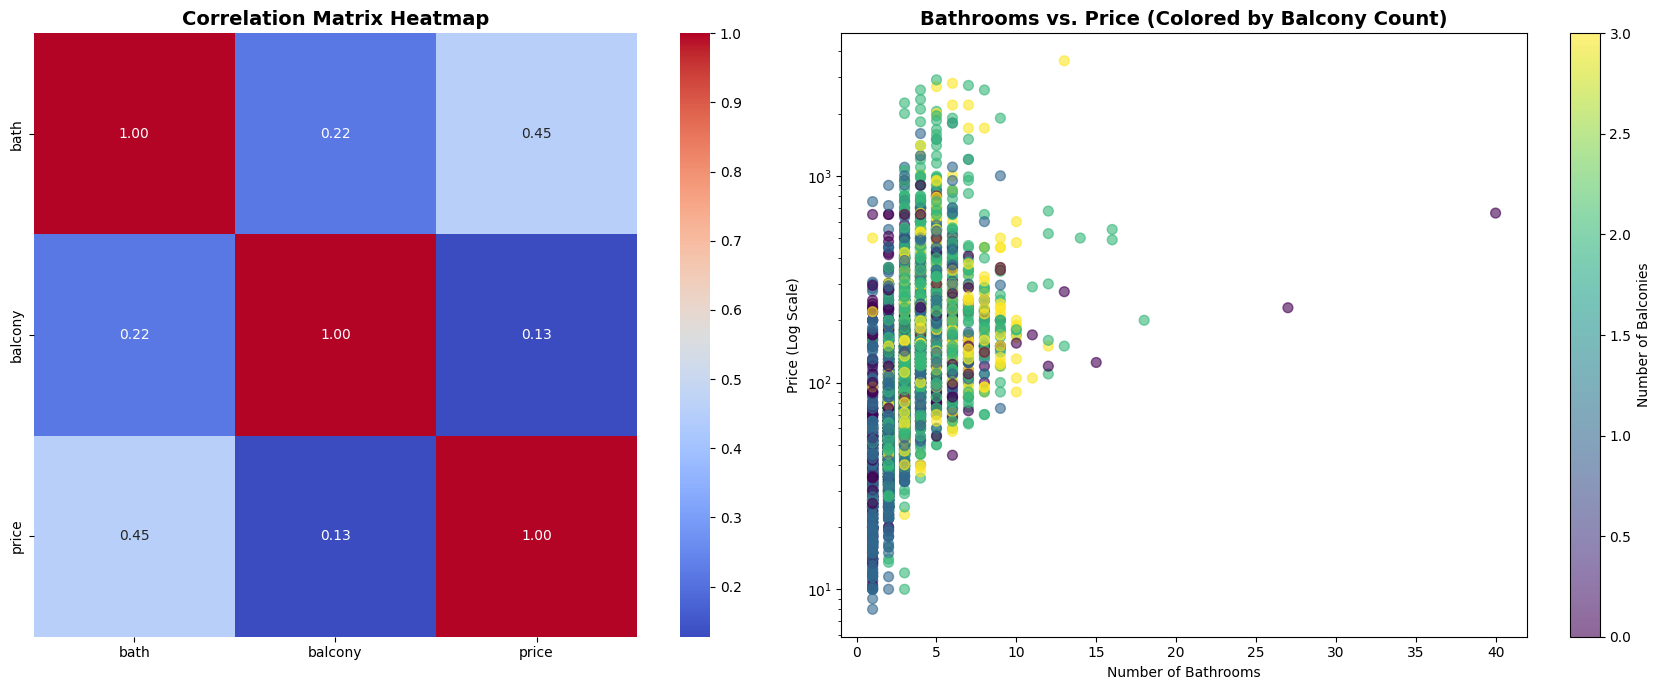

In [21]:
# Calculate Pearson correlation matrix for numerical columns
corr_matrix = df[['bath', 'balcony', 'price']].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Heatmap of correlation
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, ax=axes[0])
axes[0].set_title('Correlation Matrix Heatmap', fontsize=14, fontweight='bold')

# Scatter plot showing Bathrooms vs Price colored by Balconies
scatter = axes[1].scatter(df['bath'], df['price'], c=df['balcony'], cmap='viridis', alpha=0.6, s=50)
axes[1].set_yscale('log')
axes[1].set_title('Bathrooms vs. Price (Colored by Balcony Count)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Bathrooms')
axes[1].set_ylabel('Price (Log Scale)')
fig.colorbar(scatter, ax=axes[1], label='Number of Balconies')

plt.tight_layout()
plt.show()